# W9-D: controlled representation diagnostic at K_E=2

**Diagnostic only.** Primary W9-B remains frozen at K_E=0. This explicitly authorized FIT branch fixes K_E=2 and the cost-aware W9-C selector DraftSemantic, then compares D0 (saved draft), D1 (raw chunks), D2 (query-only extraction), and D3 (draft-aware extraction). D1/D2/D3 must use identical selected chunk IDs.

Extraction uses the existing SANE blueprint, one joint call and a 1,024-token limit for both D2/D3. Generation retains the canonical SARA context, FP16 efficient attention and 128-token limit. Extraction tables are measured as produced; exact-span support does not establish factual entailment. Compression and helpfulness are hypotheses to test.

Config: `configs/week9/w9d_k2_diagnostic.yaml`. Outputs: `results/week9/diagnostics/w9c_k2/extraction/fit/`. The shared branch name retains the completed C provenance; no primary results are replaced. Keep FREEZE_FIT=False. Full/smoke flags are disabled by default; enable the full run deliberately.


In [1]:
from pathlib import Path
import sys, json, subprocess
import pandas as pd
from IPython.display import display
ROOT = Path.cwd().resolve()
while not (ROOT / 'src/week9').is_dir():
    if ROOT == ROOT.parent:
        raise FileNotFoundError('Open this notebook within CS787-RAG-Project')
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.week9.config import load_config, load_frozen
from src.week9.runner import rows_path, phase_dir, load_phase
RUN_FULL = True
RUN_SMOKE = False
FREEZE_FIT = False
SMOKE_LIMIT = 2
SPLIT = 'fit'
assert SPLIT in ('fit', 'internal_val', 'dev')
PHASE = 'd'
CONFIG = ROOT / 'configs/week9/w9d_k2_diagnostic.yaml'
SCRIPT = ROOT / 'scripts/week9/run_w9d_representation.py'
cfg = load_config(CONFIG)


In [2]:
# Check the controlled diagnostic prerequisites before loading a GPU model.
from src.week9.runner import dependencies
if RUN_FULL or RUN_SMOKE:
    if SPLIT != 'fit':
        raise ValueError('Only FIT is prepared for this controlled diagnostic.')
    if FREEZE_FIT:
        raise ValueError('Keep FREEZE_FIT=False; inspect the diagnostic before any downstream freeze.')
    if cfg.get('diagnostic_only') is not True:
        raise ValueError('Use the separately labelled W9-D diagnostic configuration.')
    prerequisites = dependencies(cfg, PHASE, SPLIT)
    if not (prerequisites['b'].get('diagnostic_only') and
            prerequisites['b']['settings']['evidence_k'] == 2 and
            prerequisites['c'].get('diagnostic_only') and
            prerequisites['c']['settings']['selector'] == 'DraftSemantic'):
        raise ValueError('W9-D requires diagnostic K=2 and frozen DraftSemantic.')
    primary_b = load_frozen(ROOT / 'results/week9/frozen/w9b_frozen_config.json', 'b')
    if primary_b['settings']['evidence_k'] != 0:
        raise ValueError('The primary K=0 decision must remain intact.')
    print('DIAGNOSTIC ONLY: K=2, DraftSemantic; primary K=0 is unchanged.')
else:
    print('Execution disabled. Prepared diagnostic: K=2, DraftSemantic, FIT only.')


DIAGNOSTIC ONLY: K=2, DraftSemantic; primary K=0 is unchanged.


In [3]:
command = [str(ROOT / 'sara_env/bin/python'), str(SCRIPT), '--split', SPLIT,
           '--config', str(CONFIG), '--resume']
if RUN_FULL:
    if FREEZE_FIT:
        assert SPLIT == 'fit'
        command.append('--freeze')
    if PHASE == 'g':
        command.append('--collect-headroom-oof')
    subprocess.run(command, cwd=ROOT, check=True)
else:
    print('Full experiment disabled. Set RUN_FULL=True explicitly.')
if RUN_SMOKE:
    subprocess.run(command + ['--smoke-limit', str(SMOKE_LIMIT)], cwd=ROOT, check=True)


W9-D: 6984 saved real rows; complete=True; artifacts=/home/gunavenkat/Downloads/CS787-RAG-Project/results/week9/diagnostics/w9c_k2/extraction/fit


In [4]:
directory = phase_dir(cfg, PHASE, SPLIT)
path = rows_path(cfg, PHASE, SPLIT)
if path.is_file():
    rows = load_phase(cfg, PHASE, SPLIT)
    run_manifest = json.loads((directory / f'w9{PHASE}_manifest.json').read_text())
    from src.week9.provenance import digest
    expected_config = dict(cfg, _seed=run_manifest['seed'])
    if digest(expected_config) != run_manifest['config_hash']:
        raise ValueError('Notebook configuration differs from the saved run')
    print('Complete:', run_manifest['complete'], 'Rows:', len(rows))
    print('Input/source fingerprints validated by load_phase.')
    frame = pd.DataFrame(rows)
    display(frame[[c for c in ['question_id','paper_id','policy','representation','retriever',
        'retrieval_width','evidence_k','f1','total_query_prompt_tokens'] if c in frame]].head(12))
    for table in sorted(directory.glob('*.csv')):
        print(table.name)
        display(pd.read_csv(table).head(30))
else:
    print('No full-run artifacts yet. Run the phase manually; no fallback metrics were created.')


Complete: True Rows: 6984
Input/source fingerprints validated by load_phase.


,question_id,paper_id,policy,retrieval_width,evidence_k,f1,total_query_prompt_tokens
0,512,139,D0,20,0,0.800000,937
1,512,139,D1,20,2,0.705882,4110
2,512,139,D2,20,2,0.900000,6277
3,512,139,D3,20,2,0.153846,5500
4,513,139,D0,20,0,1.000000,794
5,513,139,D1,20,2,0.500000,3884
6,513,139,D2,20,2,0.800000,6051
7,513,139,D3,20,2,1.000000,5111
8,745,207,D0,20,0,0.111111,977
9,745,207,D1,20,2,0.181818,3520


w9d_summary.csv


,policy,n_queries,f1,mean_selected_delta_f1,help_selected_rate,hurt_selected_rate,exact_match,help,hurt,answer_changed,...,num_lm_calls,retrieval_query_time,selection_latency,extraction_latency,revision_latency,measured_end_to_end_latency,extraction_rate,promotion_rate,faithfulness,complexity
0,D0,1746,0.385631,0.000000,NaN,NaN,0.227950,0.000000,0.000000,0.000000,...,1.0,0.00496,8.662111e-07,NaN,NaN,NaN,0.0,0.0,NaN,0
1,D1,1746,0.385004,-0.000627,0.321306,0.281787,0.193013,0.321306,0.281787,0.762887,...,2.0,0.00496,2.936539e-01,NaN,2.261914,NaN,0.0,1.0,1.000000,1
2,D2,1746,0.368659,-0.016972,0.210767,0.238832,0.205040,0.210767,0.238832,0.646048,...,3.0,0.00496,2.932711e-01,27.692476,1.196957,NaN,1.0,1.0,0.082861,2
3,D3,1746,0.376936,-0.008695,0.186712,0.201031,0.211340,0.186712,0.201031,0.553265,...,3.0,0.00496,2.934705e-01,24.249098,1.162383,NaN,1.0,1.0,0.089785,3


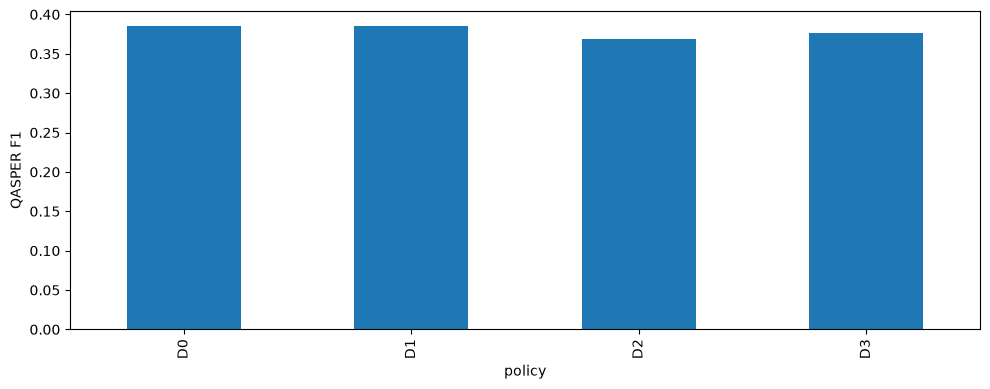

In [5]:
if path.is_file():
    import matplotlib.pyplot as plt
    if PHASE == 'a':
        table = pd.read_csv(directory / 'w9a_summary.csv')
        display(table.pivot_table(index=['representation','retriever'], columns='retrieval_width',
                                 values='all_gold_evidence_recall'))
        ax = table.pivot_table(index='representation', columns='retriever',
                              values='all_gold_evidence_recall').plot.bar(figsize=(12,5))
        ax.set_ylabel('All annotated evidence recall (paragraph proxy)')
    elif 'f1' in frame:
        group = 'evidence_k' if PHASE == 'b' else 'policy'
        ax = frame.groupby(group).f1.mean().plot.bar(figsize=(10,4))
        ax.set_ylabel('QASPER F1')
    else:
        ax = None
    if ax is not None:
        (directory / 'figures').mkdir(exist_ok=True)
        ax.figure.tight_layout()
        ax.figure.savefig(directory / 'figures' / f'w9{PHASE}_overview.png', dpi=160)
        plt.show()


## Manual decision checkpoint

Inspect completeness, source/config fingerprints, paired paper-bootstrap intervals and total query-time token costs before freezing. A smoke run cannot freeze a configuration. Summary tables come only from saved real rows. Exact-span support is separate from fact entailment, which is unmeasured unless explicitly judged. No next phase is launched here.

To regenerate summaries without loading the generator, run this phase script with `--analyze-only --resume`. Add `--freeze` only after a complete FIT run. H requires verified outer paper-fold outcomes and `--collect-oof`; see the runbook. Changes to source/config/model fingerprints require a new output root; incompatible caches are refused.


In [6]:
# Verify the controlled comparison and report extraction costs/support.
if path.is_file() and 'frame' in globals() and run_manifest.get('complete'):
    from src.week9.evaluation import paired_paper_bootstrap
    from src.week9.caching import atomic_json
    positive = frame[frame.policy.isin(['D1', 'D2', 'D3'])].copy()
    positive['selected_ids'] = positive.selected_chunk_ids.map(tuple)
    selected = positive.pivot(index=['question_id', 'paper_id'], columns='policy', values='selected_ids')
    if selected.isna().any().any() or not (selected.D1.eq(selected.D2) & selected.D1.eq(selected.D3)).all():
        raise ValueError('D1/D2/D3 must use identical selected chunks for each query.')
    print('Identical selected chunk IDs verified for D1/D2/D3.')
    print('Primary policy remains K=0; these are conditional K=2 diagnostics.')
    groups = {name: [r for r in rows if r['policy'] == name] for name in ['D0', 'D1', 'D2', 'D3']}
    baseline_comparisons = {name+'-D0': paired_paper_bootstrap(groups[name], groups['D0'], seed=run_manifest['seed'])
                            for name in ['D1', 'D2', 'D3']}
    display(pd.DataFrame(baseline_comparisons).T)
    atomic_json(directory / 'w9d_vs_saved_draft_diagnostic.json', baseline_comparisons)
    extraction_report = []
    for r in rows:
        if r.get('extraction'):
            audit = r['extraction']['audit']
            extraction_report.append(dict(question_id=r['question_id'], policy=r['policy'],
                exact_span_support_rate=audit['exact_span_support_rate'],
                empty_extraction=audit['empty_extraction'], invalid_format=audit['invalid_format'],
                reached_extraction_token_limit=r['extraction_generated_tokens'] >= cfg['extraction_max_tokens'],
                zero_exact_support=bool(audit['rows']) and not any(a['exact_span_supported'] for a in audit['rows']),
                compression_ratio=r.get('extraction_compression_ratio'),
                extraction_prompt_tokens=r['extraction_prompt_tokens'],
                extraction_generated_tokens=r['extraction_generated_tokens']))
    extraction_frame = pd.DataFrame(extraction_report)
    display(extraction_frame.groupby('policy').mean(numeric_only=True))
    print('Inspect token-cap hits and zero-support tables. Compression is measured, not guaranteed; exact-span support is not fact entailment.')
    extraction_frame.to_csv(directory / 'w9d_extraction_diagnostics.csv', index=False)
else:
    print('Controlled comparison awaits a complete saved W9-D diagnostic; no model is launched here.')


Identical selected chunk IDs verified for D1/D2/D3.
Primary policy remains K=0; these are conditional K=2 diagnostics.


,point_estimate,ci95,resamples,cluster,seed
D1-D0,-0.000627,"[-0.01813422044805145, 0.016574447845152655]",10000,paper_id,42
D2-D0,-0.016972,"[-0.03152163456936457, -0.0025867694333966173]",10000,paper_id,42
D3-D0,-0.008695,"[-0.02244586467289411, 0.004565294825139714]",10000,paper_id,42


,exact_span_support_rate,empty_extraction,invalid_format,reached_extraction_token_limit,zero_exact_support,compression_ratio,extraction_prompt_tokens,extraction_generated_tokens
policy,,,,,,,,
D2,0.082861,0.208477,0.208477,0.580183,0.686140,0.258635,3201.301833,689.160939
D3,0.089785,0.095647,0.095647,0.467927,0.768041,0.278950,3240.912371,600.183849


Inspect token-cap hits and zero-support tables. Compression is measured, not guaranteed; exact-span support is not fact entailment.
